In [1]:
import elecboltz

import numpy as np
from scipy.constants import e, m_e, hbar, electron_volt

import matplotlib as mpl
from matplotlib import pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [2]:
# matplotlib settings
# reset defaults
mpl.rcdefaults()
# font
mpl.rcParams['font.size'] = 16
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = 'Times New Roman'
mpl.rcParams['mathtext.fontset'] = 'cm'
mpl.rcParams['legend.fontsize'] = 'small'
mpl.rcParams['xtick.direction'] = 'in'
mpl.rcParams['ytick.direction'] = 'in'
mpl.rcParams['xtick.top'] = True
mpl.rcParams['ytick.right'] = True
mpl.rcParams['xtick.major.width'] = 1.0
mpl.rcParams['ytick.major.width'] = 1.0
mpl.rcParams['pdf.fonttype'] = 3
# plotting
mpl.rcParams['lines.linewidth'] = 3
mpl.rcParams['lines.markersize'] = 20

In [3]:
def calculate_drude(effective_mass, charge_density,
                    scattering_rate, magnetic_field):
    charge_mass = m_e * effective_mass
    omega_c = e * magnetic_field / charge_mass
    inverse_tensor = np.zeros((3, 3))
    np.fill_diagonal(inverse_tensor, scattering_rate)
    inverse_tensor[0, 1] = omega_c[2]
    inverse_tensor[1, 0] = -omega_c[2]
    inverse_tensor[0, 2] = -omega_c[1]
    inverse_tensor[2, 0] = omega_c[1]
    inverse_tensor[1, 2] = omega_c[0]
    inverse_tensor[2, 1] = -omega_c[0]
    return charge_density * e**2 / charge_mass * np.linalg.inv(inverse_tensor)

In [4]:
def make_bandstructure(kf, three_dimensional=False, **kwargs):
    dispersion = "Ef * (kx^2 + ky^2"
    if three_dimensional:
        dispersion += " + kz^2"
    dispersion += ") / kf^2"

    a = np.pi / kf * 1e10
    coeff = hbar**2 / (2*m_e)
    Ef = coeff * kf**2 / electron_volt * 1e3
    bandstructure = elecboltz.BandStructure(
        dispersion, Ef, [a, a, a],
        band_params={'Ef': Ef, 'kf': kf * 1e-10}, **kwargs)
    bandstructure.discretize()
    return bandstructure

In [5]:
def loop_boltzmann_and_drude(conductivity, fields, scattering, charge_density):
    sigma_boltz_xx = np.empty(len(fields))
    sigma_boltz_xy = np.empty(len(fields))
    sigma_drude_xx = np.empty(len(fields))
    sigma_drude_xy = np.empty(len(fields))
    for i, field in enumerate(fields):
        conductivity.field = np.array([0, 0, field])
        conductivity.calculate()
        sigma_boltzmann = conductivity.sigma
        sigma_drude = calculate_drude(
            1.0, charge_density, scattering * 1e12, conductivity.field)
        sigma_boltz_xx[i] = sigma_boltzmann[0, 0]
        sigma_boltz_xy[i] = sigma_boltzmann[0, 1]
        sigma_drude_xx[i] = sigma_drude[0, 0]
        sigma_drude_xy[i] = sigma_drude[0, 1]
    return (sigma_boltz_xx, sigma_boltz_xy,
            sigma_drude_xx, sigma_drude_xy)

In [6]:
kf = 1e10
charge_density = kf**3 / (2 * np.pi**2)
fields = np.linspace(0, 30, 100)
scattering = 1.0

In [7]:
resolutions = np.arange(10, 42)
errors_nonsymmetric = np.empty_like(resolutions, dtype=float)
for i, resolution in enumerate(resolutions):
    bandstructure = make_bandstructure(kf, resolution=resolution, periodic=2)
    conductivity = elecboltz.Conductivity(
        bandstructure, scattering_rate=scattering)
    sigma_boltz_xx, sigma_boltz_xy, sigma_drude_xx, sigma_drude_xy = loop_boltzmann_and_drude(
        conductivity, fields, scattering, charge_density)
    nonzeroxy = np.nonzero(sigma_drude_xy)
    errors_nonsymmetric[i] = max(
        np.max(np.abs(sigma_boltz_xx-sigma_drude_xx) / sigma_drude_xx),
        np.max(np.abs(sigma_boltz_xy-sigma_drude_xy)[nonzeroxy]
               / sigma_drude_xy[nonzeroxy]))

errors_symmetric = np.empty_like(resolutions, dtype=float)
for i, resolution in enumerate(resolutions):
    bandstructure = make_bandstructure(
        kf, resolution=resolution, periodic=2, symmetry='tetragonal')
    conductivity = elecboltz.Conductivity(
        bandstructure, scattering_rate=scattering)
    sigma_boltz_xx, sigma_boltz_xy, sigma_drude_xx, sigma_drude_xy = loop_boltzmann_and_drude(
        conductivity, fields, scattering, charge_density)
    nonzeroxy = np.nonzero(sigma_drude_xy)
    errors_symmetric[i] = max(
        np.max(np.abs(sigma_boltz_xx-sigma_drude_xx) / sigma_drude_xx),
        np.max(np.abs(sigma_boltz_xy-sigma_drude_xy)[nonzeroxy]
               / sigma_drude_xy[nonzeroxy]))

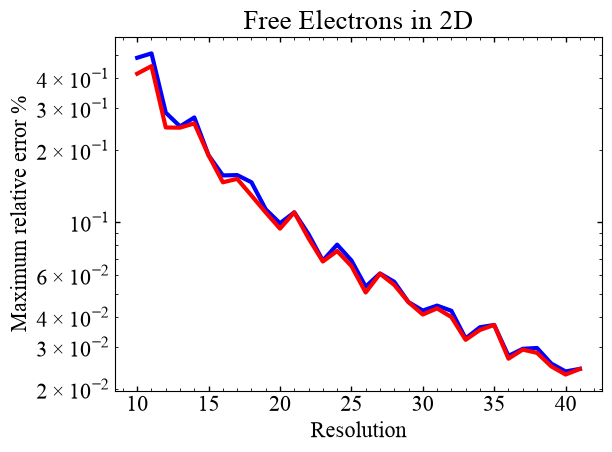

In [34]:
plt.semilogy(resolutions, 100 * errors_nonsymmetric, color='blue', label='No Symmetry')
plt.semilogy(resolutions, 100 * errors_symmetric, color='red', label='Symmetric')
plt.minorticks_on()
plt.xlabel("Resolution")
plt.ylabel("Maximum relative error %")
plt.title("Free Electrons in 2D")
plt.tight_layout()
plt.savefig("symmetry_error.pdf", bbox_inches='tight')
plt.savefig("symmetry_error.png", bbox_inches='tight',
            dpi=300)
plt.show()

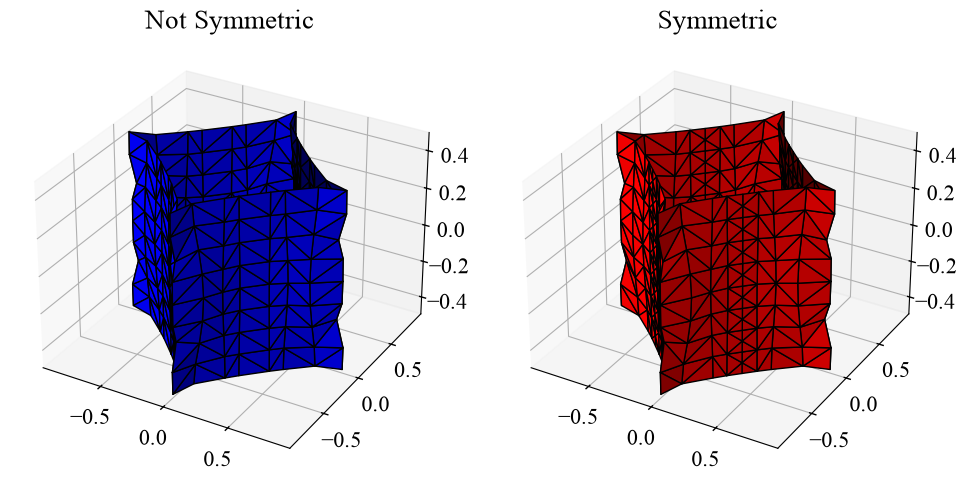

In [ ]:
params = {
    'band_name': "Nd-LSCO",
    'a': 3.75,
    'b': 3.75,
    'c': 13.2,
    'energy_scale': 160,
    'band_params': {'mu': -0.82439881, 't': 1, 'tp': -0.13642799,
                    'tpp': 0.06816836, 'tz': 0.06512192},
    'resolution': 9,
    'periodic': 2,
    'domain_size': [1.0, 1.0, 2.0],
    'symmetry': None
}
band_asym = elecboltz.BandStructure(**elecboltz.easy_params(params))
band_asym.discretize()
params['symmetry'] = 'tetragonal'
band_sym = elecboltz.BandStructure(**elecboltz.easy_params(params))
band_sym.discretize()

fig, axs = plt.subplots(1, 2, subplot_kw={'projection': '3d'}, figsize=(10, 5))
axs[0].plot_trisurf(
    band_asym.kpoints[:, 0], band_asym.kpoints[:, 1], band_asym.kpoints[:, 2],
    triangles=band_asym.kfaces, color='blue', edgecolor='black', lw=1)
axs[1].plot_trisurf(
    band_sym.kpoints[:, 0], band_sym.kpoints[:, 1], band_sym.kpoints[:, 2],
    triangles=band_sym.kfaces, color='red', edgecolor='black', lw=1)
axs[0].set_title("Not Symmetric")
axs[1].set_title("Symmetric")
plt.tight_layout()
plt.savefig("symmetry_bands_oddres.pdf", bbox_inches='tight')
plt.show()

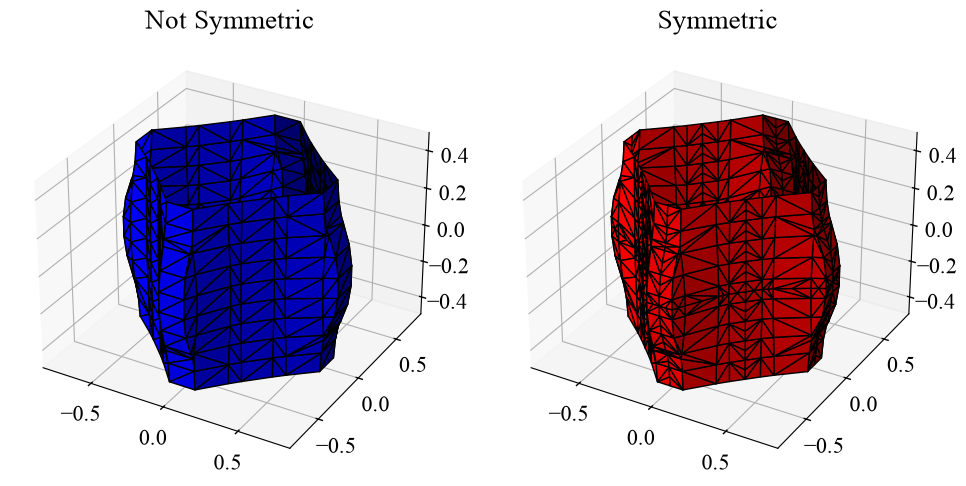

In [ ]:
params = {
    'band_name': "Nd-LSCO",
    'a': 3.75,
    'b': 3.75,
    'c': 13.2,
    'energy_scale': 160,
    'band_params': {'mu': -0.82439881, 't': 1, 'tp': -0.13642799,
                    'tpp': 0.06816836, 'tz': 0.06512192},
    'resolution': 10,
    'periodic': 2,
    'domain_size': [1.0, 1.0, 2.0],
    'symmetry': None
}
band_asym = elecboltz.BandStructure(**elecboltz.easy_params(params))
band_asym.discretize()
params['symmetry'] = 'tetragonal'
band_sym = elecboltz.BandStructure(**elecboltz.easy_params(params))
band_sym.discretize()

fig, axs = plt.subplots(1, 2, subplot_kw={'projection': '3d'}, figsize=(10, 5))
axs[0].plot_trisurf(
    band_asym.kpoints[:, 0], band_asym.kpoints[:, 1], band_asym.kpoints[:, 2],
    triangles=band_asym.kfaces, color='blue', edgecolor='black', lw=1)
axs[1].plot_trisurf(
    band_sym.kpoints[:, 0], band_sym.kpoints[:, 1], band_sym.kpoints[:, 2],
    triangles=band_sym.kfaces, color='red', edgecolor='black', lw=1)
axs[0].set_title("Not Symmetric")
axs[1].set_title("Symmetric")
plt.tight_layout()
plt.savefig("symmetry_bands_evenres.pdf", bbox_inches='tight')
plt.show()